# Experiment notebook: label smoothing on Fashion-MNIST

This is the full, runnable experiment behind the blog post **"Is That Your Final Answer? What Label Smoothing Does to an Overconfident CNN"**.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-GITHUB-USERNAME/label-smoothing-blog/blob/main/label_smoothing_experiment.ipynb)

**Question:** how does the label-smoothing strength ε change a small CNN's accuracy and confidence on Fashion-MNIST?

**What it does**
1. Trains the class `SmallCNN` five times, once for each ε in {0, 0.05, 0.1, 0.2, 0.3}. Everything else stays fixed.
2. Logs learning curves and calibration metrics on the **validation set** after every epoch. The test set is never used.
3. Saves the figures to `figures/` and the numbers to `results/`.
4. Repeats the five runs with two more seeds (43, 44) to check that the pattern isn't luck.

**Runtime:** about 6 seconds per epoch on a 2-core CPU, so roughly 25 minutes for all 15 runs. A free Colab GPU is faster. Set `SEEDS = [42]` for a 5-run version that takes about 8 minutes.

**Credit:** the data module, model, `HParams` config and `fit()` helper are reused from the class notebook `hyperparameters_lightning.ipynb`. The changes are marked `# NEW`.

In [1]:
# Colab ships with torch and torchvision; Lightning needs installing once.
import importlib.util, subprocess, sys
if importlib.util.find_spec("lightning") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightning"], check=True)

In [2]:
import json
import logging
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import lightning as L
from lightning.pytorch.callbacks import EarlyStopping
from lightning.pytorch.loggers import CSVLogger

warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")
warnings.filterwarnings("ignore", message=".*LeafSpec.*")

print("torch:", torch.__version__, "| lightning:", L.__version__, "| GPU:", torch.cuda.is_available())

torch: 2.15.0+cpu | lightning: 2.6.6 | GPU: False


## 1. All hyperparameters in one place

Same `HParams` as the class notebook, plus one new field: `label_smoothing` (ε).

In [3]:
@dataclass
class HParams:
    # ---- Data -------------------------------------------------------------
    data_dir: str = "./data"
    batch_size: int = 64
    val_fraction: float = 0.1
    train_subset: Optional[int] = None
    augment: bool = False
    num_workers: int = 0

    # ---- Model ------------------------------------------------------------
    conv1_channels: int = 32
    conv2_channels: int = 64
    hidden_dim: int = 128
    activation: str = "relu"
    use_batchnorm: bool = True
    dropout: float = 0.25

    # ---- Optimisation -----------------------------------------------------
    optimizer: str = "adam"
    lr: float = 1e-3
    momentum: float = 0.9
    weight_decay: float = 0.0
    scheduler: str = "none"
    label_smoothing: float = 0.0  # NEW: epsilon, the share of target probability spread over all classes

    # ---- Training loop ----------------------------------------------------
    max_epochs: int = 5
    patience: int = 3
    seed: int = 42


# The experiment: the ONLY thing that changes between runs is label_smoothing.
EPSILONS = [0.0, 0.05, 0.1, 0.2, 0.3]
SEEDS = [42, 43, 44]          # 42 = main run (all figures); 43 and 44 = "is it luck?" check
MAIN_SEED = 42
EXP = replace(HParams(), train_subset=10_000, max_epochs=15, patience=100)  # patience=100 -> every run lasts 15 epochs

FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)
pd.Series(asdict(EXP), name="value").to_frame()

,value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,10000
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


## 2. Data (unchanged from the class notebook)

60,000 training images are split once into 54,000 for training and 6,000 for validation, using the seed. Only the first 10,000 training images are used, to keep runs short. **All 6,000 validation images are used** for every comparison. The 10,000 test images are loaded but never evaluated.

In [4]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
FMNIST_MEAN, FMNIST_STD = (0.2860,), (0.3530,)


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        normalize = transforms.Normalize(FMNIST_MEAN, FMNIST_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])
        augmentations = []
        if hp.augment:
            augmentations = [transforms.RandomCrop(28, padding=2), transforms.RandomHorizontalFlip()]
        self.train_transform = transforms.Compose([*augmentations, transforms.ToTensor(), normalize])

    def prepare_data(self):
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        train_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.train_transform)
        eval_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.eval_transform)
        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_idx, train_idx = indices[:n_val], indices[n_val:]
        if self.hp.train_subset is not None:
            train_idx = train_idx[: self.hp.train_subset]
        self.train_ds = Subset(train_view, train_idx)
        self.val_ds = Subset(eval_view, val_idx)
        self.test_ds = datasets.FashionMNIST(self.hp.data_dir, train=False, transform=self.eval_transform)

    def _loader(self, dataset, batch_size, shuffle):
        return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                          num_workers=self.hp.num_workers, persistent_workers=self.hp.num_workers > 0)

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, shuffle=True)

    def val_dataloader(self):
        return self._loader(self.val_ds, 512, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, shuffle=False)

## 3. Model (unchanged from the class notebook)

In [5]:
ACTIVATIONS = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU, "tanh": nn.Tanh}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]
        c1, c2 = hp.conv1_channels, hp.conv2_channels

        def conv_block(in_ch, out_ch):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
            if hp.use_batchnorm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [act(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(conv_block(1, c1), conv_block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),
            nn.Linear(c2 * 7 * 7, hp.hidden_dim),
            act(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(f"trainable parameters: {count_parameters(SmallCNN(EXP)):,}")

trainable parameters: 421,834


## 4. Training logic, with label smoothing and calibration metrics

Three changes to the class `LitClassifier`, all marked `# NEW`:

1. **Training loss uses ε.** `F.cross_entropy(..., label_smoothing=ε)` is the only line that differs between runs.
2. **Validation loss is always the plain (unsmoothed) cross-entropy.** A smoothed loss can't go below a floor that grows with ε (about 0.50 at ε = 0.1), so smoothed losses aren't comparable across runs. The plain version is: it's the average of −log p(true class). It's also called NLL (negative log-likelihood).
3. **Calibration is measured on the validation set every epoch:**
   - **confidence:** the highest softmax probability;
   - **ECE (expected calibration error):** split predictions into 15 confidence bins, then take the size-weighted average gap between confidence and accuracy in each bin;
   - **gap:** mean confidence minus accuracy, so + means overconfident and − means underconfident.

In [6]:
def calibration_bins(conf: torch.Tensor, correct: torch.Tensor, n_bins: int = 15):
    # NEW: per-bin count, mean confidence and accuracy (equal-width bins on (0, 1]).
    edges = torch.linspace(0, 1, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        n = int(in_bin.sum())
        rows.append({"lo": lo.item(), "hi": hi.item(), "count": n,
                     "confidence": conf[in_bin].mean().item() if n else np.nan,
                     "accuracy": correct[in_bin].float().mean().item() if n else np.nan})
    return pd.DataFrame(rows)


def expected_calibration_error(conf: torch.Tensor, correct: torch.Tensor, n_bins: int = 15) -> float:
    # NEW: ECE = sum over bins of (bin share) * |bin accuracy - bin confidence|  (Guo et al., 2017)
    bins = calibration_bins(conf, correct, n_bins).dropna()
    weights = bins["count"] / len(conf)
    return float((weights * (bins["accuracy"] - bins["confidence"]).abs()).sum())


class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))
        self.model = SmallCNN(hp)
        self._val_conf, self._val_correct = [], []

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y, label_smoothing=self.hp.label_smoothing)  # NEW: the one line that changes
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train_nll", F.cross_entropy(logits, y), on_step=False, on_epoch=True)  # NEW: plain loss, comparable across eps
        self.log("train_acc", (logits.argmax(1) == y).float().mean(), on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def on_validation_epoch_start(self):
        self._val_conf, self._val_correct = [], []

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        conf, pred = F.softmax(logits, dim=1).max(dim=1)
        self._val_conf.append(conf.detach().cpu())
        self._val_correct.append((pred == y).detach().cpu())
        self.log("val_loss", F.cross_entropy(logits, y), on_step=False, on_epoch=True, prog_bar=True)  # NEW: always unsmoothed
        self.log("val_acc", (pred == y).float().mean(), on_step=False, on_epoch=True, prog_bar=True)

    def on_validation_epoch_end(self):
        # NEW: calibration metrics over the whole validation set
        conf, correct = torch.cat(self._val_conf), torch.cat(self._val_correct)
        self.log("val_ece", expected_calibration_error(conf, correct))
        self.log("val_conf", conf.mean())
        self.log("val_gap", conf.mean() - correct.float().mean())

    def configure_optimizers(self):
        hp = self.hp
        if hp.optimizer == "sgd":
            return torch.optim.SGD(self.parameters(), lr=hp.lr, momentum=hp.momentum, weight_decay=hp.weight_decay)
        if hp.optimizer == "adam":
            return torch.optim.Adam(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        if hp.optimizer == "adamw":
            return torch.optim.AdamW(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        raise ValueError(f"unknown optimizer: {hp.optimizer}")

## 5. The `fit()` helper (from the class notebook)

The only change is `num_sanity_val_steps=0`, so the calibration lists start empty in every epoch.

In [7]:
METRICS = ["train_loss", "train_nll", "train_acc", "val_loss", "val_acc", "val_ece", "val_conf", "val_gap"]


def load_history(log_dir) -> pd.DataFrame:
    df = pd.read_csv(Path(log_dir) / "metrics.csv")
    cols = [c for c in METRICS if c in df.columns]
    hist = df.groupby("epoch")[cols].mean().reset_index()
    hist["epoch"] = hist["epoch"] + 1  # count epochs from 1
    return hist


def fit(hp: HParams, run_name: str = "run", verbose: bool = False):
    for name in ("lightning.pytorch", "lightning.fabric", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.INFO if verbose else logging.ERROR)
    L.seed_everything(hp.seed, workers=True, verbose=False)
    datamodule = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("logs", name=run_name)
    trainer = L.Trainer(
        max_epochs=hp.max_epochs,
        accelerator="auto",
        devices=1,
        logger=logger,
        callbacks=[EarlyStopping(monitor="val_loss", mode="min", patience=hp.patience)],
        enable_checkpointing=False,
        enable_progress_bar=verbose,
        enable_model_summary=verbose,
        num_sanity_val_steps=0,  # NEW
        log_every_n_steps=10,
    )
    trainer.fit(model, datamodule=datamodule)
    return model, datamodule, load_history(logger.log_dir)


@torch.no_grad()
def predict_val(model: LitClassifier, dm: FashionMNISTDataModule):
    # Softmax probabilities and labels for every validation image (final weights, eval mode).
    model.eval()
    probs, labels = [], []
    for x, y in dm.val_dataloader():
        probs.append(F.softmax(model(x.to(model.device)), dim=1).cpu())
        labels.append(y)
    return torch.cat(probs), torch.cat(labels)

## 6. Run the experiment

One run per (seed, ε). For the main seed, the validation predictions from the final epoch are kept for the calibration figures.

In [8]:
import time

histories, val_preds = [], {}
for seed in SEEDS:
    for eps in EPSILONS:
        hp = replace(EXP, label_smoothing=eps, seed=seed)
        start = time.perf_counter()
        model, dm, hist = fit(hp, run_name=f"ls_seed{seed}_eps{eps:g}")
        hist.insert(0, "seed", seed)
        hist.insert(1, "eps", eps)
        histories.append(hist)
        if seed == MAIN_SEED:
            val_preds[eps] = predict_val(model, dm)
        last = hist.iloc[-1]
        print(f"seed {seed}  eps={eps:<4}  val_acc={last.val_acc:.4f}  val_loss={last.val_loss:.4f}  "
              f"ECE={last.val_ece:.4f}  ({time.perf_counter() - start:.0f}s)")

history = pd.concat(histories, ignore_index=True)
history.to_csv(RES_DIR / "history_all_runs.csv", index=False)
# Save the main seed's final validation predictions so figures 3 and 4 can be redrawn without retraining.
np.savez_compressed(RES_DIR / f"val_preds_seed{MAIN_SEED}.npz",
                    **{f"eps{e:g}_probs": p.numpy() for e, (p, _) in val_preds.items()},
                    labels=next(iter(val_preds.values()))[1].numpy())

seed 42  eps=0.0   val_acc=0.8925  val_loss=0.3242  ECE=0.0287  (114s)


seed 42  eps=0.05  val_acc=0.8887  val_loss=0.3319  ECE=0.0278  (104s)


seed 42  eps=0.1   val_acc=0.8993  val_loss=0.3528  ECE=0.0753  (98s)


seed 42  eps=0.2   val_acc=0.9012  val_loss=0.4562  ECE=0.1675  (94s)


seed 42  eps=0.3   val_acc=0.8998  val_loss=0.5728  ECE=0.2537  (99s)


seed 43  eps=0.0   val_acc=0.8995  val_loss=0.2856  ECE=0.0259  (96s)


... (5 outputs left out)

seed 44  eps=0.05  val_acc=0.9028  val_loss=0.3131  ECE=0.0277  (104s)


seed 44  eps=0.1   val_acc=0.9000  val_loss=0.3635  ECE=0.0768  (102s)


seed 44  eps=0.2   val_acc=0.9032  val_loss=0.4724  ECE=0.1836  (105s)


seed 44  eps=0.3   val_acc=0.9068  val_loss=0.5813  ECE=0.2692  (101s)


## 7. Figures

Plot style: the baseline (ε = 0, no smoothing) is orange. Smoothed runs are blue, getting darker as ε grows.

In [9]:
EPS_COLORS = {0.0: "#eb6834", 0.05: "#86b6ef", 0.1: "#3987e5", 0.2: "#1c5cab", 0.3: "#0d366b"}
EPS_LABEL = {e: ("ε = 0 (no smoothing)" if e == 0 else f"ε = {e:g}") for e in EPSILONS}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "lines.linewidth": 2,
})
main = history[history.seed == MAIN_SEED]

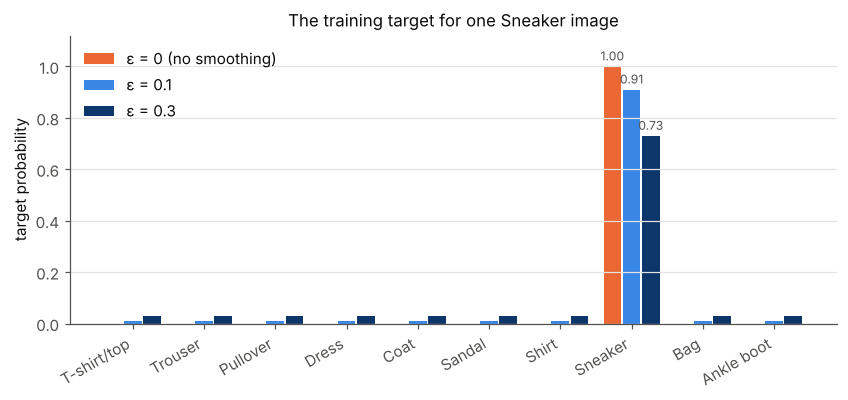

In [10]:
# Figure 1: what the network is told to aim for (an explainer, not a result).
K, true_class = 10, CLASS_NAMES.index("Sneaker")
show_eps = [0.0, 0.1, 0.3]
x = np.arange(K)
width = 0.27
fig, ax = plt.subplots(figsize=(9, 3.4))
for i, eps in enumerate(show_eps):
    target = np.full(K, eps / K)
    target[true_class] += 1 - eps
    ax.bar(x + (i - 1) * width, target, width * 0.92, color=EPS_COLORS[eps], label=EPS_LABEL[eps])
    ax.annotate(f"{target[true_class]:.2f}", (true_class + (i - 1) * width, target[true_class]),
                ha="center", va="bottom", fontsize=8, color=INK_2, xytext=(0, 2), textcoords="offset points")
ax.set_xticks(x, CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("target probability")
ax.set_ylim(0, 1.12)
ax.set_title("The training target for one Sneaker image")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "fig1_targets.png")
plt.show()

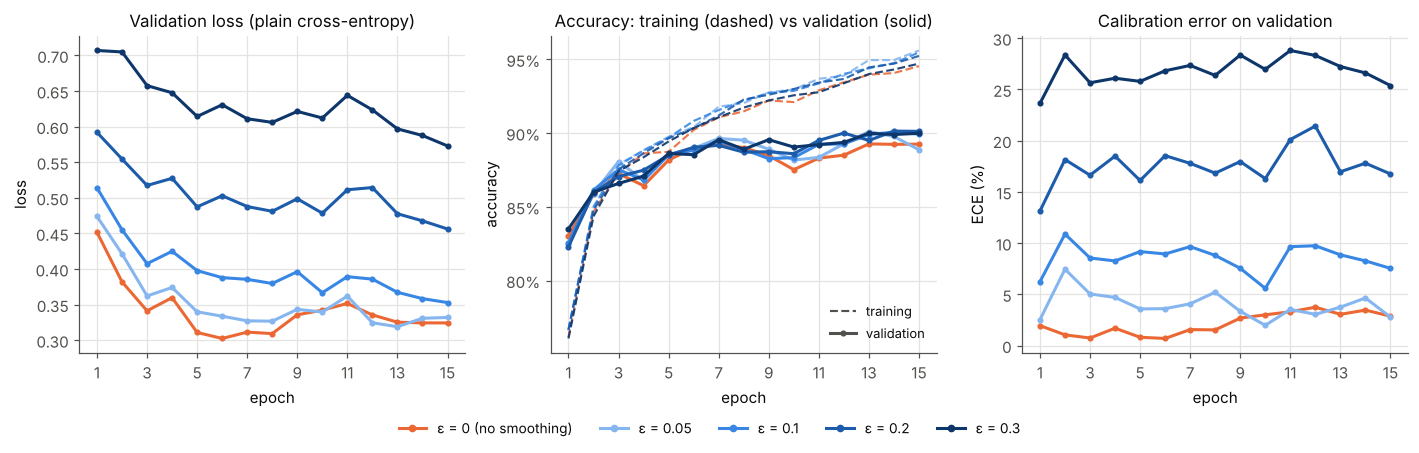

In [11]:
# Figure 2: learning curves for the main seed.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
ax_loss, ax_acc, ax_ece = axes
for eps in EPSILONS:
    h = main[main.eps == eps]
    c = EPS_COLORS[eps]
    ax_loss.plot(h.epoch, h.val_loss, "-o", ms=3, color=c, label=EPS_LABEL[eps])
    ax_acc.plot(h.epoch, h.train_acc, "--", lw=1.4, color=c, alpha=0.9)
    ax_acc.plot(h.epoch, h.val_acc, "-o", ms=3, color=c)
    ax_ece.plot(h.epoch, h.val_ece * 100, "-o", ms=3, color=c)

ax_loss.set(title="Validation loss (plain cross-entropy)", xlabel="epoch", ylabel="loss")
ax_acc.set(title="Accuracy: training (dashed) vs validation (solid)", xlabel="epoch", ylabel="accuracy")
ax_ece.set(title="Calibration error on validation", xlabel="epoch", ylabel="ECE (%)")
from matplotlib.ticker import MultipleLocator
ax_acc.yaxis.set_major_locator(MultipleLocator(0.05))
ax_acc.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in axes:
    ax.set_xticks(range(1, EXP.max_epochs + 1, 2))
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color=EPS_COLORS[e], marker="o", ms=4, label=EPS_LABEL[e]) for e in EPSILONS],
           loc="lower center", ncol=len(EPSILONS), bbox_to_anchor=(0.5, -0.06), fontsize=9)
ax_acc.legend(handles=[Line2D([], [], color=INK_2, ls="--", lw=1.4, label="training"),
                       Line2D([], [], color=INK_2, ls="-", marker="o", ms=3, label="validation")],
              fontsize=8.5, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_learning_curves.png")
plt.show()

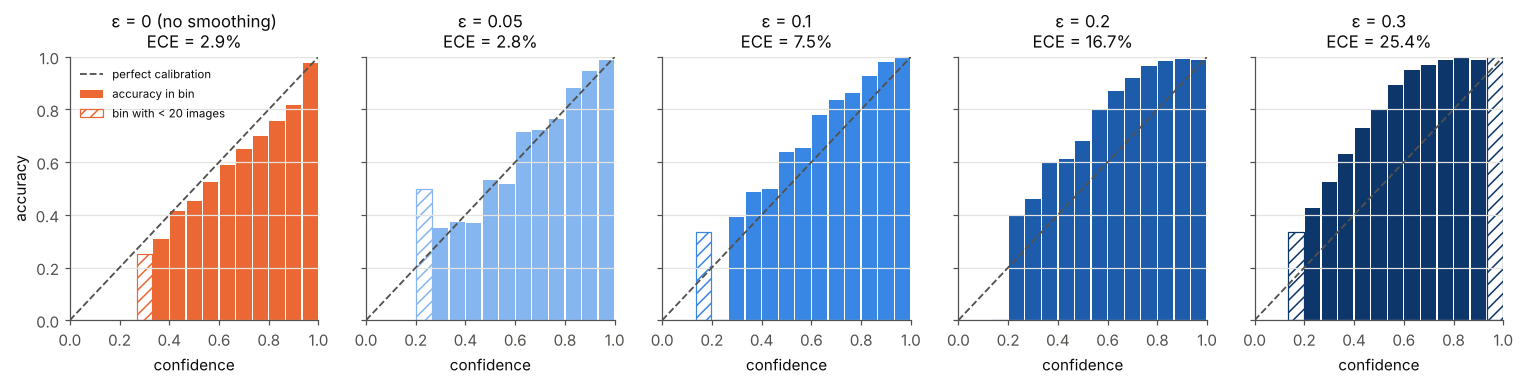

In [12]:
# Figure 3: reliability diagrams after the final epoch (main seed).
fig, axes = plt.subplots(1, len(EPSILONS), figsize=(14, 3.6), sharey=True)
for ax, eps in zip(axes, EPSILONS):
    probs, labels = val_preds[eps]
    conf, pred = probs.max(dim=1)
    correct = pred == labels
    bins = calibration_bins(conf, correct)
    ece = expected_calibration_error(conf, correct)
    centers = (bins.lo + bins.hi) / 2
    width = bins.hi - bins.lo
    enough = bins["count"] >= 20
    ax.bar(centers[enough], bins.accuracy[enough], width[enough] * 0.92, color=EPS_COLORS[eps], label="accuracy in bin")
    ax.bar(centers[~enough & (bins["count"] > 0)], bins.accuracy[~enough & (bins["count"] > 0)],
           width[~enough & (bins["count"] > 0)] * 0.92, color="none", edgecolor=EPS_COLORS[eps],
           hatch="///", lw=0.8, label="bin with < 20 images")
    ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color=INK_2, label="perfect calibration")
    ax.set(title=f"{EPS_LABEL[eps]}\nECE = {ece:.1%}", xlabel="confidence", xlim=(0, 1), ylim=(0, 1))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("accuracy")
axes[0].legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_reliability.png")
plt.show()

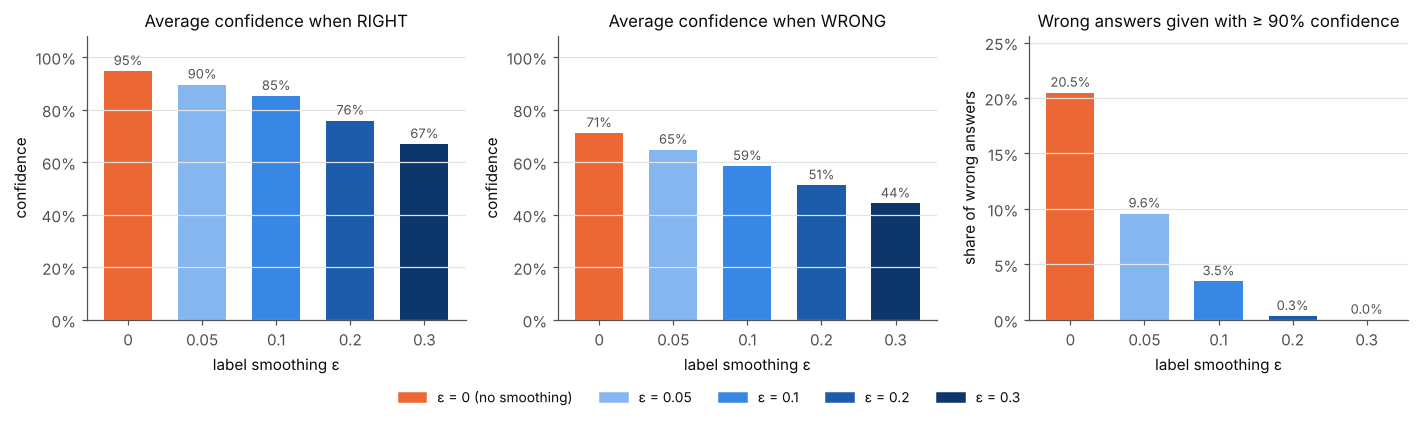

,eps,conf_right,conf_wrong,wrong_over_90,n_wrong
0,0.00,0.946529,0.710655,0.204651,645
1,0.05,0.895168,0.647071,0.095808,668
2,0.10,0.851746,0.585107,0.034768,604
3,0.20,0.758137,0.512042,0.003373,593
4,0.30,0.668696,0.443059,0.000000,601


In [13]:
# Figure 4: the "trust me bro" meter: how sure is the model when it is right vs when it is wrong?
rows = []
for eps in EPSILONS:
    probs, labels = val_preds[eps]
    conf, pred = probs.max(dim=1)
    correct = pred == labels
    rows.append({"eps": eps,
                 "conf_right": conf[correct].mean().item(),
                 "conf_wrong": conf[~correct].mean().item(),
                 "wrong_over_90": (conf[~correct] >= 0.9).float().mean().item(),
                 "n_wrong": int((~correct).sum())})
meter = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
panels = [("conf_right", "Average confidence when RIGHT", "confidence"),
          ("conf_wrong", "Average confidence when WRONG", "confidence"),
          ("wrong_over_90", "Wrong answers given with ≥ 90% confidence", "share of wrong answers")]
xpos = np.arange(len(EPSILONS))
for ax, (col, title, ylabel) in zip(axes, panels):
    vals = meter[col].to_numpy()
    small = col == "wrong_over_90"          # this panel has its own, zoomed-in scale
    ax.bar(xpos, vals, 0.65, color=[EPS_COLORS[e] for e in EPSILONS])
    for xi, v in zip(xpos, vals):
        ax.annotate(f"{v:.1%}" if small else f"{v:.0%}", (xi, v), ha="center", va="bottom", fontsize=8.5,
                    color=INK_2, xytext=(0, 2), textcoords="offset points")
    ax.set(title=title, ylabel=ylabel, ylim=(0, max(vals) * 1.25 if small else 1.08))
    ax.set_xticks(xpos, [f"{e:g}" for e in EPSILONS])
    ax.set_xlabel("label smoothing ε")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=EPS_COLORS[e], label=EPS_LABEL[e]) for e in EPSILONS],
           loc="lower center", ncol=len(EPSILONS), bbox_to_anchor=(0.5, -0.07), fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_trust_me_bro_meter.png")
plt.show()
meter

## 8. Results tables

In [14]:
# Table 1: main seed, after the final epoch (epoch 15), all metrics on the 6,000 validation images.
final = main.groupby("eps").tail(1).set_index("eps")
best = main.loc[main.groupby("eps")["val_loss"].idxmin()].set_index("eps")
table1 = pd.DataFrame({
    "val accuracy": final.val_acc,
    "val loss (plain CE)": final.val_loss,
    "lowest val loss": best.val_loss,
    "epoch of lowest val loss": best.epoch.astype(int),
    "ECE": final.val_ece,
    "mean confidence": final.val_conf,
    "confidence - accuracy": final.val_gap,
}).join(meter.set_index("eps")[["conf_wrong", "wrong_over_90"]].rename(
    columns={"conf_wrong": "confidence when wrong", "wrong_over_90": "wrong with >=90% conf"}))
table1.to_csv(RES_DIR / "table1_main_seed.csv")
table1.style.format("{:.4f}").format({"epoch of lowest val loss": "{:d}"})

,val accuracy,val loss (plain CE),lowest val loss,epoch of lowest val loss,ECE,mean confidence,confidence - accuracy,confidence when wrong,wrong with >=90% conf
eps,,,,,,,,,
0.000000,0.892500,0.324228,0.302409,6,0.028673,0.921173,0.028673,0.710655,0.204651
0.050000,0.888667,0.331894,0.318893,13,0.027758,0.867546,-0.021120,0.647071,0.095808
0.100000,0.899333,0.352828,0.352828,15,0.075312,0.824905,-0.074429,0.585107,0.034768
0.200000,0.901167,0.456171,0.456171,15,0.167468,0.733814,-0.167352,0.512042,0.003373
0.300000,0.899833,0.572822,0.572822,15,0.253739,0.646095,-0.253739,0.443059,0.000000


In [15]:
# Table 2: the "is it luck?" check. Final-epoch metrics, mean +/- std over the seeds.
last_epoch = history[history.epoch == EXP.max_epochs]
agg = last_epoch.groupby("eps")[["val_acc", "val_loss", "val_ece", "val_gap"]].agg(["mean", "std"])
agg.to_csv(RES_DIR / "table2_seed_check.csv")
table2 = pd.DataFrame({m: [f"{agg.loc[e, (m, 'mean')]:.4f} ± {agg.loc[e, (m, 'std')]:.4f}" for e in agg.index]
                       for m in ["val_acc", "val_loss", "val_ece", "val_gap"]}, index=agg.index)
print("seeds:", sorted(history.seed.unique().tolist()))
table2

seeds: [42, 43, 44]


,val_acc,val_loss,val_ece,val_gap
eps,,,,
0.00,0.8932 ± 0.0059,0.3356 ± 0.0566,0.0366 ± 0.0161,0.0366 ± 0.0161
0.05,0.8957 ± 0.0071,0.3207 ± 0.0099,0.0286 ± 0.0014,-0.0260 ± 0.0044
0.10,0.8981 ± 0.0028,0.3545 ± 0.0083,0.0700 ± 0.0106,-0.0696 ± 0.0105
0.20,0.9018 ± 0.0012,0.4582 ± 0.0134,0.1730 ± 0.0092,-0.1728 ± 0.0089
0.30,0.9027 ± 0.0037,0.5769 ± 0.0043,0.2624 ± 0.0079,-0.2624 ± 0.0079


## 9. Numbers to quote in the blog post

If you rerun the notebook, copy these into the post so the text matches your figures.

In [16]:
numbers = {
    "params": count_parameters(SmallCNN(EXP)),
    "main_seed_final": table1.round(4).reset_index().to_dict(orient="records"),
    "seed_check": {str(e): {m: [round(agg.loc[e, (m, "mean")], 4), round(agg.loc[e, (m, "std")], 4)]
                            for m in ["val_acc", "val_loss", "val_ece", "val_gap"]} for e in agg.index},
    "baseline_val_loss_by_epoch": main[main.eps == 0].val_loss.round(4).tolist(),
    "baseline_train_acc_final": round(float(main[main.eps == 0].train_acc.iloc[-1]), 4),
}
(RES_DIR / "numbers_for_blog.json").write_text(json.dumps(numbers, indent=2))
print(json.dumps(numbers, indent=2))

{
  "params": 421834,
  "main_seed_final": [
    {
      "eps": 0.0,
      "val accuracy": 0.8925,
      "val loss (plain CE)": 0.3242,
      "lowest val loss": 0.3024,
      "epoch of lowest val loss": 6,
      "ECE": 0.0287,
      "mean confidence": 0.9212,
      "confidence - accuracy": 0.0287,
      "confidence when wrong": 0.7107,
      "wrong with >=90% conf": 0.2047
    },
    {
      "eps": 0.05,
      "val accuracy": 0.8887,
      "val loss (plain CE)": 0.3319,
      "lowest val loss": 0.3189,
      "epoch of lowest val loss": 13,
      "ECE": 0.0278,
      "mean confidence": 0.8675,
      "confidence - accuracy": -0.0211,
      "confidence when wrong": 0.6471,
      "wrong with >=90% conf": 0.0958
    },
    {
      "eps": 0.1,
      "val accuracy": 0.8993,
      "val loss (plain CE)": 0.3528,
      "lowest val loss": 0.3528,
      "epoch of lowest val loss": 15,
      "ECE": 0.0753,
      "mean confidence": 0.8249,
      "confidence - accuracy": -0.0744,
      "confidence wh

In [17]:
import platform
print("python", platform.python_version(), "| torch", torch.__version__, "| lightning", L.__version__,
      "| device:", "GPU" if torch.cuda.is_available() else "CPU")

python 3.13.18 | torch 2.15.0+cpu | lightning 2.6.6 | device: CPU
